# 04 · Reproducción del artículo tal cual
**Proyecto Integrador ML2 — Segunda entrega · Predicción de la TRM**

**Objetivo (rúbrica 7.3, "el método del artículo se reproduce").** Aplicar a la TRM el método de Eslami Ghayour y Yousefi (2023) **sin cambios**, para ver qué pasa y justificar con evidencia la adaptación. Pone a prueba la **hipótesis H6** del EDA: *el método en niveles falla fuera del rango de entrenamiento*.

**Qué dice el artículo y qué no.** Predice el precio de cierre diario con LightGBM, CatBoost y XGBoost, normaliza con MinMax y divide 80/20, con parámetros por defecto (solo CatBoost se ajusta solo). **No describe sus variables predictoras** ni si el corte respeta el orden temporal, y su repositorio público solo contiene los precios de cierre, sin el código del modelo. Se toma la lectura más literal y se declara:

| Elemento | Decisión | Por qué |
|---|---|---|
| Objetivo | TRM del día siguiente, **en nivel** | Es lo que predice el artículo |
| Variables | TRM rezagada 1, 5 y 10 días, **en nivel** | Los rezagos de la Entrega 1; el artículo solo usa el precio |
| Normalización | MinMax a variables y objetivo, **ajustado solo con entrenamiento** | Ajustarlo con todos los datos sería fuga |
| Partición | 80/20 **cronológica** | La lectura sin fuga de la del artículo |
| Modelos | LightGBM, CatBoost y XGBoost con parámetros por defecto, semilla 42 | Tal cual el artículo |
| Contraste | La línea base de la Entrega 1 (regresión lineal) sobre las mismas variables en nivel | Para separar el efecto del algoritmo |

**Dónde se evalúa.** El 80/20 se aplica **dentro del desarrollo** (2003–2022) y no sobre el conjunto completo, para no abrir el test antes del notebook 06. La falla que se busca también ocurre dentro del desarrollo, porque en su último tramo la TRM supera todo lo anterior.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from xgboost import XGBRegressor

from src import config as cfg
from src.graficos import estilo, guardar_figura, guardar_tabla, COLORES

estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
datos = pd.read_csv(cfg.DATA_PROC / "dataset.csv", parse_dates=["fecha"])
dev = datos[datos["muestra"] == "desarrollo"].reset_index(drop=True)       # el test NO se usa aquí

# Variables del artículo: la TRM en nivel rezagada 1, 5 y 10 días (TRM_t, TRM_{t-4}, TRM_{t-9})
dev["trm_l1"], dev["trm_l5"], dev["trm_l10"] = dev["trm"], dev["trm"].shift(4), dev["trm"].shift(9)
X_COLS = ["trm_l1", "trm_l5", "trm_l10"]
art = dev.dropna(subset=X_COLS).reset_index(drop=True)

corte = int(round(len(art) * 0.8))
entren, evalua = art.iloc[:corte], art.iloc[corte:]
assert entren["fecha"].max() < evalua["fecha"].min()
print(f"Entrenamiento: {len(entren):,} días, {entren['fecha'].min().date()} a {entren['fecha'].max().date()} "
      f"| TRM máxima {entren['trm_sig'].max():,.2f}")
print(f"Evaluación:    {len(evalua):,} días, {evalua['fecha'].min().date()} a {evalua['fecha'].max().date()} "
      f"| TRM máxima {evalua['trm_sig'].max():,.2f}")
print(f"Días de evaluación con la TRM por encima del máximo de entrenamiento: "
      f"{(evalua['trm_sig'] > entren['trm_sig'].max()).mean():.1%}")

Entrenamiento: 3,449 días, 2003-12-31 a 2018-07-17 | TRM máxima 3,434.89
Evaluación:    862 días, 2018-07-18 a 2022-03-01 | TRM máxima 4,153.91
Días de evaluación con la TRM por encima del máximo de entrenamiento: 59.0%


## 1. Entrenamiento con parámetros por defecto
Cada modelo va en un `Pipeline` con MinMax sobre las variables y un `TransformedTargetRegressor` que aplica MinMax también al objetivo. Los dos escaladores se ajustan **solo con el entrenamiento**.

In [2]:
def reproduccion(modelo):
    return TransformedTargetRegressor(
        regressor=Pipeline([("minmax", MinMaxScaler()), ("modelo", modelo)]),
        transformer=MinMaxScaler())

modelos = {
    "LightGBM": LGBMRegressor(random_state=cfg.SEMILLA, verbose=-1),
    "CatBoost": CatBoostRegressor(random_seed=cfg.SEMILLA, verbose=0, allow_writing_files=False),
    "XGBoost": XGBRegressor(random_state=cfg.SEMILLA),
    "Lineal (línea base, en nivel)": LinearRegression(),
}
pred = {}
for nombre, m in modelos.items():
    pred[nombre] = reproduccion(m).fit(entren[X_COLS], entren["trm_sig"]).predict(evalua[X_COLS])

max_entren = entren["trm_sig"].max()
filas = []
for nombre, p in pred.items():
    real, hoy = evalua["trm_sig"].to_numpy(), evalua["trm"].to_numpy()
    filas.append({"modelo": nombre,
                  "rmse_pesos": np.sqrt(np.mean((real - p) ** 2)), "mae_pesos": np.mean(np.abs(real - p)),
                  "r2_niveles": r2_score(real, p),
                  "r2_retornos": r2_score(np.log(real / hoy), np.log(p / hoy)),
                  "prediccion_maxima": p.max(), "supera_max_entrenamiento": bool(p.max() > max_entren)})
repro = pd.DataFrame(filas).set_index("modelo")
guardar_tabla(repro, "tab04_reproduccion_articulo")
display(repro)

# Diagnóstico de la métrica (no es un modelo): "mañana igual que hoy"
copia = evalua["trm"].to_numpy()
print(f"Diagnóstico: copiar la TRM de hoy daría R² en niveles = {r2_score(evalua['trm_sig'], copia):.4f} "
      f"sin ningún modelo.")

,rmse_pesos,mae_pesos,r2_niveles,r2_retornos,prediccion_maxima,supera_max_entrenamiento
modelo,,,,,,
LightGBM,332.6007,245.0227,-0.1456,-143.8819,"3,368.3780",False
CatBoost,317.2278,230.7966,-0.0422,-129.8025,"3,393.6349",False
XGBoost,318.4878,234.2131,-0.0505,-130.9853,"3,418.4253",False
"Lineal (línea base, en nivel)",27.9044,20.1102,0.9919,0.0016,"4,158.2797",True


Diagnóstico: copiar la TRM de hoy daría R² en niveles = 0.9919 sin ningún modelo.


## 2. Figura 3: el techo de la extrapolación

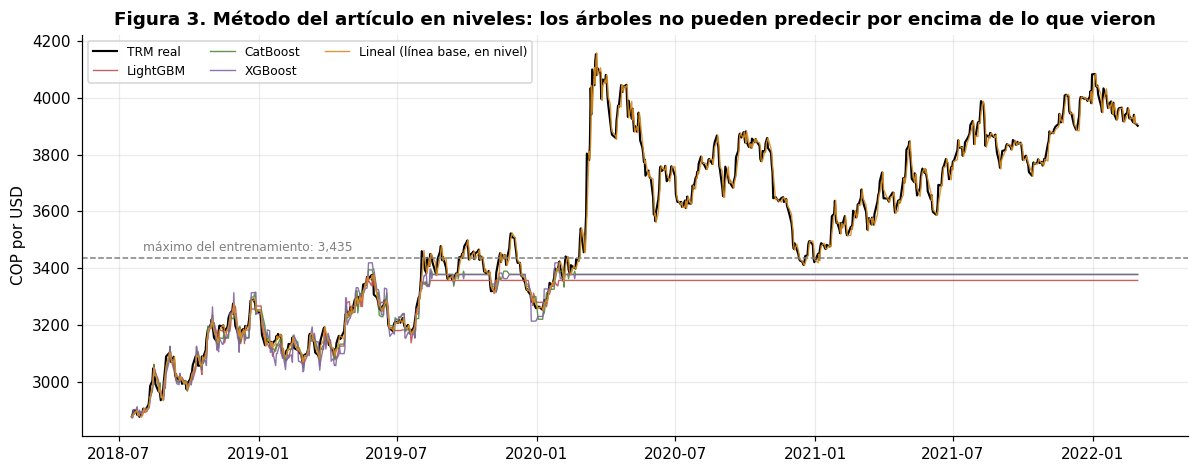

In [3]:
fig, eje = plt.subplots(figsize=(11, 4.4))
eje.plot(evalua["fecha"], evalua["trm_sig"], color="black", lw=1.4, label="TRM real")
for (nombre, p), c in zip(pred.items(), COLORES[1:]):
    eje.plot(evalua["fecha"], p, color=c, lw=0.9, alpha=0.9, label=nombre)
eje.axhline(max_entren, color="grey", ls="--", lw=1)
eje.text(evalua["fecha"].iloc[10], max_entren + 25, f"máximo del entrenamiento: {max_entren:,.0f}", fontsize=8, color="grey")
eje.set(ylabel="COP por USD",
        title="Figura 3. Método del artículo en niveles: los árboles no pueden predecir por encima de lo que vieron")
eje.legend(fontsize=8, ncol=3)
fig.tight_layout(); guardar_figura(fig, "fig03_techo_extrapolacion"); plt.show()

## Conclusión: qué dice la reproducción

**Se confirma H6, y con más fuerza de la esperada.** En el tramo de evaluación, del 18 de julio de 2018 al 1 de marzo de 2022, la TRM supera el máximo del entrenamiento (3.434,89) en el **59 % de los días**. Los tres boosting **nunca** predicen por encima de ese techo: sus predicciones máximas son 3.368 (LightGBM), 3.394 (CatBoost) y 3.418 (XGBoost). Desde el choque del COVID, en marzo de 2020, las tres quedan **planas** mientras la TRM sube a más de 4.100 (Figura 3).

**Por qué ocurre.** Un árbol predice el promedio de los valores de entrenamiento que caen en cada hoja, así que ninguna hoja puede valer más que el máximo que vio. El boosting suma árboles que corrigen a los anteriores **dentro del mismo rango**, así que la predicción total también queda atrapada. No es un problema de ajuste de hiperparámetros: es la forma en que funcionan los árboles, y el EDA ya lo anticipaba (E1: los niveles no son estacionarios).

**Las consecuencias en las métricas:**
- **Los tres boosting tienen un RMSE de 317 a 333 pesos**, alrededor de **12 veces** el de la línea base lineal sobre las mismas variables (**28 pesos**), que sí sigue a la TRM porque una recta puede pasar de cualquier valor visto.
- **Su R² en niveles es negativo** (de −0,04 a −0,15): predicen peor que la media del periodo.
- **El R² en niveles engaña a favor de cualquiera que copie el pasado.** La línea base obtiene 0,992, y copiar la TRM de hoy, sin ningún modelo, da exactamente lo mismo (0,992). Un R² alto en niveles no distingue un modelo útil de uno que no hace nada. Por eso, desde la Entrega 1, el R² se calcula **sobre retornos**.
- **Medido sobre retornos, la línea base en niveles explica apenas el 0,16 % de la variación diaria** (R² = 0,0016): en niveles, la regresión lineal casi solo copia la TRM de hoy.

**Qué justifica, en el orden del informe:**
1. **Objetivo en retornos:** los árboles pueden predecir un retorno de un tamaño ya visto aunque el nivel sea nuevo, porque el nivel se reconstruye desde la TRM de hoy.
2. **R² sobre retornos:** es la única versión de la métrica que mide capacidad de predicción.
3. **La adaptación respeta el propósito del artículo** (comparar los tres boosting en una serie cambiaria diaria) y corrige lo que impide que la comparación sea válida en la TRM.

**Limitación.** El artículo no documenta sus variables; si usó otras, por ejemplo indicadores técnicos, el techo sería el mismo, porque cualquier modelo de árboles entrenado sobre precios en nivel lo tiene. Esta reproducción se hizo dentro del desarrollo para no abrir el test; en el notebook 06 se evalúa también sobre el test, junto con los demás modelos.